# Noise2Motion
### A Controlled Study of Noise Schedules in a Small Video DDPM

**Author:** Asmamaw | **Program:** iCog Labs AGI Internship
**Task:** Implement and train a small video DDPM in PyTorch (8 frames, 32×32, grayscale)

**Planned experiments:** linear vs. cosine schedule, ε- vs. v-prediction, EMA, sampling-step speed/quality, failure-case analysis

In [1]:
# ============================================================
# Noise2Motion | Cell 1: Setup, reproducibility, and config
# ============================================================
import os, sys, json, random, platform
from dataclasses import dataclass, asdict
import numpy as np
import torch

# ---------- 1. Google Drive + project folders (with fallback) ----------
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/noise2motion'
    print('Drive mounted: results will persist.')
except Exception as e:
    PROJECT_DIR = '/content/noise2motion'
    print('Drive mount failed:', e)
    print('Using local storage. Files will be LOST when the runtime resets,')
    print('so download checkpoints and logs manually.')

for sub in ['checkpoints', 'logs', 'samples']:
    os.makedirs(f'{PROJECT_DIR}/{sub}', exist_ok=True)

# ---------- 2. Device check ----------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    props = torch.cuda.get_device_properties(0)
    print(f'GPU: {props.name} | {props.total_memory / 1e9:.1f} GB')
else:
    print('WARNING: no GPU found. Use Runtime > Change runtime type > T4 GPU.')

# ---------- 3. Reproducibility ----------
def set_seed(seed: int, deterministic: bool = True):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

# ---------- 4. Central config (saved with every run) ----------
@dataclass
class Config:
    # data
    num_frames: int = 8
    image_size: int = 32
    channels: int = 1
    n_train: int = 5000
    n_val: int = 500
    train_data_seed: int = 1      # separate seeds -> separate splits
    val_data_seed: int = 2

    # diffusion
    T: int = 1000
    schedule: str = 'linear'      # 'linear' or 'cosine'
    prediction_target: str = 'eps'  # 'eps' now, 'v' later as an ablation

    # model
    base_channels: int = 64
    time_emb_dim: int = 256

    # training
    seed: int = 42
    batch_size: int = 64
    lr: float = 2e-4
    train_steps: int = 5000
    ema_decay: float = 0.999

cfg = Config()

def save_config(cfg: Config, run_name: str):
    path = f'{PROJECT_DIR}/logs/{run_name}_config.json'
    with open(path, 'w') as f:
        json.dump(asdict(cfg), f, indent=2)
    return path

set_seed(cfg.seed)

# ---------- 5. Environment record (for the README) ----------
print('\n--- Environment ---')
print('Python :', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('NumPy  :', np.__version__)
print('CUDA   :', torch.version.cuda)
print('OS     :', platform.platform())
print('\n--- Config ---')
print(json.dumps(asdict(cfg), indent=2))
print('\nProject folder:', PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted: results will persist.
GPU: Tesla T4 | 15.6 GB

--- Environment ---
Python : 3.13.15
PyTorch: 2.11.0+cu130
NumPy  : 2.1.3
CUDA   : 13.0
OS     : Linux-6.6.122+-x86_64-with-glibc2.39

--- Config ---
{
  "num_frames": 8,
  "image_size": 32,
  "channels": 1,
  "n_train": 5000,
  "n_val": 500,
  "train_data_seed": 1,
  "val_data_seed": 2,
  "T": 1000,
  "schedule": "linear",
  "prediction_target": "eps",
  "base_channels": 64,
  "time_emb_dim": 256,
  "seed": 42,
  "batch_size": 64,
  "lr": 0.0002,
  "train_steps": 5000,
  "ema_decay": 0.999
}

Project folder: /content/drive/MyDrive/noise2motion


Train clips : 5000 | Val clips: 500
Batch shape : (64, 1, 8, 32, 32) (expected B x 1 x 8 x 32 x 32)
Value range : -1.0 to 1.0
Mean pixel  : -0.855 (mostly background, so below 0)
Train/val different: True


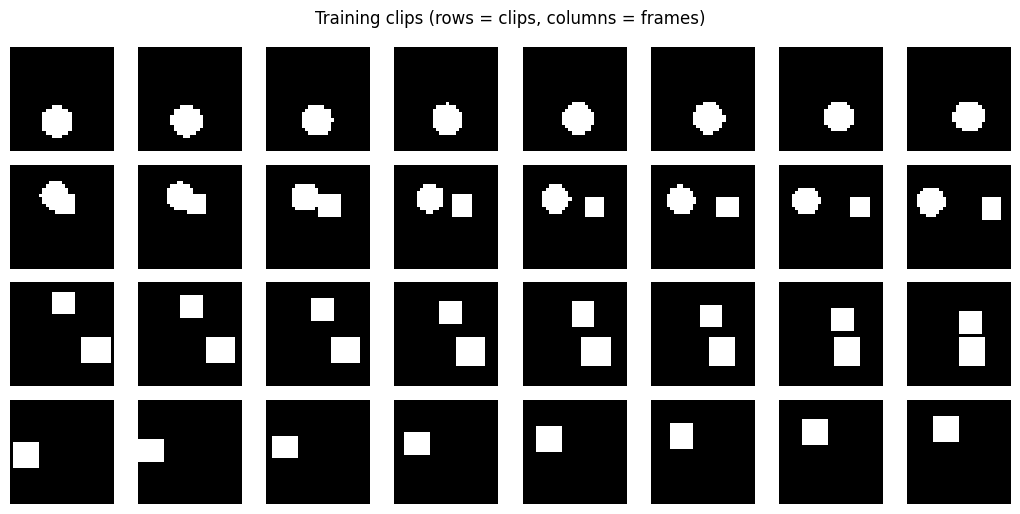

In [2]:
# ============================================================
# Noise2Motion | Cell 2: Procedural moving-shape dataset
# ============================================================
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

def render_frame(shapes, size):
    """Draw all shapes onto one binary frame (overlaps are merged)."""
    yy, xx = np.mgrid[0:size, 0:size].astype(np.float32)
    frame = np.zeros((size, size), dtype=np.float32)
    for s in shapes:
        if s['kind'] == 'circle':
            mask = (xx - s['x'])**2 + (yy - s['y'])**2 <= s['r']**2
        else:  # square
            mask = (np.abs(xx - s['x']) <= s['r']) & (np.abs(yy - s['y']) <= s['r'])
        frame = np.maximum(frame, mask.astype(np.float32))
    return frame

def make_clip(rng, num_frames, size, speed_range=(0.5, 2.0)):
    """Simulate 1-2 shapes moving at constant velocity, bouncing off the walls."""
    n_shapes = rng.integers(1, 3)  # 1 or 2 shapes
    shapes = []
    for _ in range(n_shapes):
        r = rng.uniform(2.0, 5.0)
        speed = rng.uniform(*speed_range)
        angle = rng.uniform(0, 2 * np.pi)
        shapes.append({
            'kind': 'circle' if rng.random() < 0.5 else 'square',
            'r': r,
            'x': rng.uniform(r, size - 1 - r),
            'y': rng.uniform(r, size - 1 - r),
            'vx': speed * np.cos(angle),
            'vy': speed * np.sin(angle),
        })

    frames = []
    for _ in range(num_frames):
        frames.append(render_frame(shapes, size))
        for s in shapes:                      # move, then bounce off walls
            s['x'] += s['vx']; s['y'] += s['vy']
            if s['x'] - s['r'] < 0:        s['x'] = s['r'];            s['vx'] = abs(s['vx'])
            if s['x'] + s['r'] > size - 1: s['x'] = size - 1 - s['r']; s['vx'] = -abs(s['vx'])
            if s['y'] - s['r'] < 0:        s['y'] = s['r'];            s['vy'] = abs(s['vy'])
            if s['y'] + s['r'] > size - 1: s['y'] = size - 1 - s['r']; s['vy'] = -abs(s['vy'])
    return np.stack(frames)                   # (F, H, W), values in {0, 1}

class MovingShapes(Dataset):
    """Generates all clips once (deterministic given the seed) and keeps them in memory."""
    def __init__(self, n_clips, num_frames, size, seed):
        rng = np.random.default_rng(seed)
        clips = np.stack([make_clip(rng, num_frames, size) for _ in range(n_clips)])
        clips = clips[:, None]                # (N, 1, F, H, W)
        self.data = torch.from_numpy(clips * 2.0 - 1.0)   # normalize to [-1, 1]

    def __len__(self):
        return len(self.data)

    def __getitem__(self, i):
        return self.data[i]

# ---------- Build train / validation splits (separate seeds) ----------
train_ds = MovingShapes(cfg.n_train, cfg.num_frames, cfg.image_size, cfg.train_data_seed)
val_ds   = MovingShapes(cfg.n_val,   cfg.num_frames, cfg.image_size, cfg.val_data_seed)

train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True,
                          drop_last=True, num_workers=0)
val_loader   = DataLoader(val_ds, batch_size=cfg.batch_size, shuffle=False, num_workers=0)

# ---------- Sanity checks ----------
x = next(iter(train_loader))
print('Train clips :', len(train_ds), '| Val clips:', len(val_ds))
print('Batch shape :', tuple(x.shape), '(expected B x 1 x 8 x 32 x 32)')
print('Value range :', x.min().item(), 'to', x.max().item())
print('Mean pixel  :', round(x.mean().item(), 3), '(mostly background, so below 0)')
print('Train/val different:', not torch.equal(train_ds.data[:10], val_ds.data[:10]))

# ---------- Visual check: 4 clips, 8 frames each ----------
def show_clips(clips, n=4, title='', save_path=None):
    n = min(n, len(clips))
    F = clips.shape[2]
    fig, axes = plt.subplots(n, F, figsize=(F * 1.3, n * 1.3))
    for i in range(n):
        for f in range(F):
            axes[i, f].imshow(clips[i, 0, f].cpu(), cmap='gray', vmin=-1, vmax=1)
            axes[i, f].axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120)
    plt.show()

show_clips(train_ds.data, n=4, title='Training clips (rows = clips, columns = frames)',
           save_path=f'{PROJECT_DIR}/samples/dataset_preview.png')

--- Schedule check ---
linear  | abar[0]=0.99990  abar[T/2]=0.0778  abar[T-1]=4.04e-05  beta range=(1.0e-04, 0.020)
cosine  | abar[0]=0.99996  abar[T/2]=0.4923  abar[T-1]=2.43e-09  beta range=(4.1e-05, 0.999)
linear  | x_T mean=-0.005 std=0.999 (want ~0 and ~1) | max |x_1 - x0|=0.050
cosine  | x_T mean=-0.001 std=0.997 (want ~0 and ~1) | max |x_1 - x0|=0.029


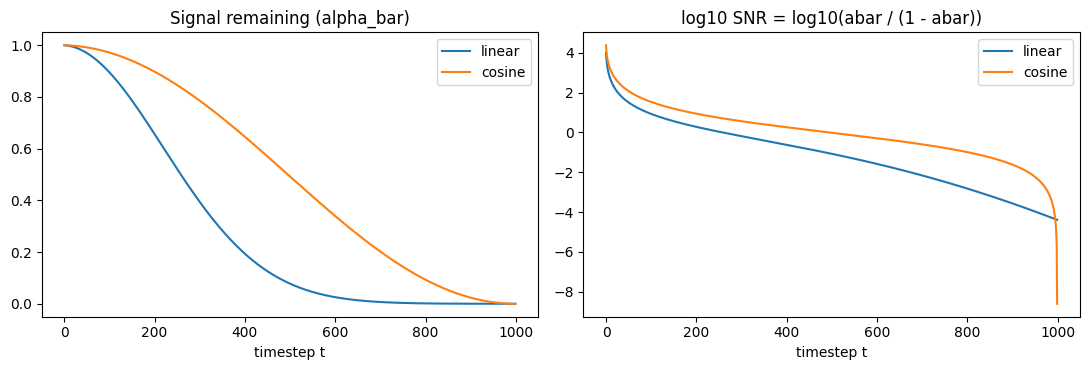

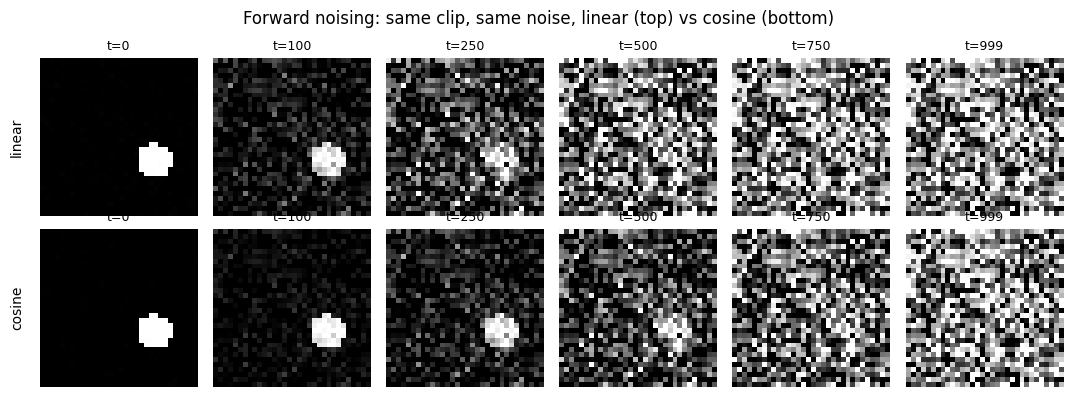

In [3]:
# ============================================================
# Noise2Motion | Cell 3: Noise schedules + forward diffusion
# ============================================================
import math
import torch
import matplotlib.pyplot as plt

def make_betas(schedule, T):
    if schedule == 'linear':
        return torch.linspace(1e-4, 0.02, T, dtype=torch.float64)
    elif schedule == 'cosine':
        s = 0.008
        steps = torch.arange(T + 1, dtype=torch.float64)
        f = torch.cos(((steps / T + s) / (1 + s)) * math.pi / 2) ** 2
        alpha_bar = f / f[0]
        betas = 1 - alpha_bar[1:] / alpha_bar[:-1]
        return betas.clamp(max=0.999)
    raise ValueError(f'Unknown schedule: {schedule}')

class Diffusion:
    """Holds the schedule tensors and implements the forward process q(x_t | x_0)."""
    def __init__(self, schedule, T, device):
        self.schedule, self.T = schedule, T
        betas = make_betas(schedule, T)
        alphas = 1.0 - betas
        alpha_bar = torch.cumprod(alphas, dim=0)

        to32 = lambda v: v.float().to(device)
        self.betas      = to32(betas)
        self.alphas     = to32(alphas)
        self.alpha_bar  = to32(alpha_bar)
        self.sqrt_ab    = to32(alpha_bar.sqrt())
        self.sqrt_1mab  = to32((1 - alpha_bar).sqrt())

    def q_sample(self, x0, t, noise=None):
        """x_t = sqrt(abar_t) * x0 + sqrt(1 - abar_t) * eps"""
        if noise is None:
            noise = torch.randn_like(x0)
        a = self.sqrt_ab[t].view(-1, 1, 1, 1, 1)
        b = self.sqrt_1mab[t].view(-1, 1, 1, 1, 1)
        return a * x0 + b * noise

diffusions = {name: Diffusion(name, cfg.T, device) for name in ['linear', 'cosine']}

# ---------- Sanity checks ----------
print('--- Schedule check ---')
for name, d in diffusions.items():
    print(f'{name:7s} | abar[0]={d.alpha_bar[0].item():.5f}  '
          f'abar[T/2]={d.alpha_bar[cfg.T//2].item():.4f}  '
          f'abar[T-1]={d.alpha_bar[-1].item():.2e}  '
          f'beta range=({d.betas.min().item():.1e}, {d.betas.max().item():.3f})')

x0 = next(iter(train_loader)).to(device)
for name, d in diffusions.items():
    t_last = torch.full((x0.size(0),), cfg.T - 1, device=device)
    xT = d.q_sample(x0, t_last)
    t_zero = torch.zeros(x0.size(0), dtype=torch.long, device=device)
    x_small = d.q_sample(x0, t_zero)
    print(f'{name:7s} | x_T mean={xT.mean().item():+.3f} std={xT.std().item():.3f} '
          f'(want ~0 and ~1) | max |x_1 - x0|={(x_small - x0).abs().max().item():.3f}')

# ---------- Plot 1: signal remaining and SNR ----------
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, d in diffusions.items():
    ab = d.alpha_bar.cpu()
    ax[0].plot(ab, label=name)
    ax[1].plot(torch.log10(ab / (1 - ab)), label=name)
ax[0].set_title('Signal remaining (alpha_bar)'); ax[0].set_xlabel('timestep t'); ax[0].legend()
ax[1].set_title('log10 SNR = log10(abar / (1 - abar))'); ax[1].set_xlabel('timestep t'); ax[1].legend()
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/samples/schedule_curves.png', dpi=120)
plt.show()

# ---------- Plot 2: one clip noised at increasing t (middle frame shown) ----------
ts = [0, 100, 250, 500, 750, 999]
clip = x0[:1]
fig, axes = plt.subplots(2, len(ts), figsize=(len(ts) * 1.8, 4))
for r, (name, d) in enumerate(diffusions.items()):
    torch.manual_seed(0)
    noise = torch.randn_like(clip)
    for c, t in enumerate(ts):
        xt = d.q_sample(clip, torch.tensor([t], device=device), noise)
        axes[r, c].imshow(xt[0, 0, cfg.num_frames // 2].cpu().clamp(-1, 1), cmap='gray', vmin=-1, vmax=1)
        axes[r, c].set_title(f't={t}', fontsize=9)
        axes[r, c].axis('off')
    axes[r, 0].text(-0.1, 0.5, name, transform=axes[r, 0].transAxes,
                    rotation=90, va='center', ha='right', fontsize=10)
plt.suptitle('Forward noising: same clip, same noise, linear (top) vs cosine (bottom)')
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/samples/forward_noising.png', dpi=120)
plt.show()

In [4]:
# ============================================================
# Noise2Motion | Cell 4: Timestep embedding + 3D-conv denoiser
# ============================================================
import math, time
import torch, torch.nn as nn, torch.nn.functional as F

def timestep_embedding(t, dim):
    """Sinusoidal features of the integer timestep -> (B, dim)."""
    half = dim // 2
    freqs = torch.exp(-math.log(10000) *
                      torch.arange(half, device=t.device, dtype=torch.float32) / half)
    args = t.float()[:, None] * freqs[None, :]
    return torch.cat([args.sin(), args.cos()], dim=1)

class ResBlock3D(nn.Module):
    """GroupNorm -> SiLU -> Conv3d, with the timestep embedding added in the middle."""
    def __init__(self, in_ch, out_ch, emb_dim, groups=8):
        super().__init__()
        self.norm1 = nn.GroupNorm(groups, in_ch)
        self.conv1 = nn.Conv3d(in_ch, out_ch, 3, padding=1)
        self.emb_proj = nn.Linear(emb_dim, out_ch)
        self.norm2 = nn.GroupNorm(groups, out_ch)
        self.conv2 = nn.Conv3d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv3d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb_proj(F.silu(emb))[:, :, None, None, None]  # broadcast over F,H,W
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class VideoDenoiser(nn.Module):
    """
    Small U-Net style denoiser for clips (B, C, F, H, W).
    - 3D kernels connect neighboring frames.
    - Downsampling is SPATIAL only: frame count is never reduced, so frames stay aligned.
    - Output has exactly the same shape as the input (predicts noise, or v later).
    """
    def __init__(self, in_ch=1, base=64, emb_dim=256):
        super().__init__()
        self.emb_dim = emb_dim
        self.time_mlp = nn.Sequential(
            nn.Linear(emb_dim, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))

        self.stem = nn.Conv3d(in_ch, base, 3, padding=1)
        self.down_blocks = nn.ModuleList([ResBlock3D(base, base, emb_dim) for _ in range(2)])

        self.downsample = nn.Conv3d(base, base * 2, 3, stride=(1, 2, 2), padding=1)
        self.mid_blocks = nn.ModuleList([ResBlock3D(base * 2, base * 2, emb_dim) for _ in range(2)])

        self.upsample = nn.Upsample(scale_factor=(1, 2, 2), mode='nearest')
        self.up_conv = nn.Conv3d(base * 2, base, 3, padding=1)
        self.up_blocks = nn.ModuleList([
            ResBlock3D(base * 2, base, emb_dim),   # input = upsampled + skip (concat)
            ResBlock3D(base, base, emb_dim)])

        self.out_norm = nn.GroupNorm(8, base)
        self.out_conv = nn.Conv3d(base, in_ch, 3, padding=1)

    def forward(self, x, t):
        emb = self.time_mlp(timestep_embedding(t, self.emb_dim))
        h = self.stem(x)
        for blk in self.down_blocks:
            h = blk(h, emb)
        skip = h
        h = self.downsample(h)
        for blk in self.mid_blocks:
            h = blk(h, emb)
        h = self.up_conv(self.upsample(h))
        h = torch.cat([h, skip], dim=1)
        for blk in self.up_blocks:
            h = blk(h, emb)
        return self.out_conv(F.silu(self.out_norm(h)))

model = VideoDenoiser(cfg.channels, cfg.base_channels, cfg.time_emb_dim).to(device)

# ---------- Tests ----------
n_params = sum(p.numel() for p in model.parameters())
print(f'Parameters: {n_params / 1e6:.2f} M')

x = next(iter(train_loader)).to(device)
t = torch.randint(0, cfg.T, (x.size(0),), device=device)
eps = torch.randn_like(x)
xt = diffusions['linear'].q_sample(x, t, eps)

# 1. Shape preservation
out = model(xt, t)
print('Input shape :', tuple(xt.shape), '| Output shape:', tuple(out.shape))
assert out.shape == xt.shape, 'Output shape must equal input shape'

# 2. Gradients flow to every parameter
model.zero_grad(set_to_none=True)
loss = (out - eps).square().mean()
loss.backward()
no_grad = [n for n, p in model.named_parameters() if p.grad is None or p.grad.abs().sum() == 0]
print('Initial loss:', round(loss.item(), 4), '(expect around 1.0 for an untrained model)')
print('Params with missing/zero gradient:', no_grad if no_grad else 'none')

# 3. The model actually uses the timestep
model.eval()
with torch.no_grad():
    o1 = model(xt, torch.full_like(t, 10))
    o2 = model(xt, torch.full_like(t, 900))
print('Output change when only t differs:', (o1 - o2).abs().mean().item(), '(must be > 0)')

# 4. Frames interact (3D convs): perturb one input frame, check other frames' outputs change
with torch.no_grad():
    xp = xt.clone(); xp[:, :, 3] += 1.0
    d = (model(xp, t) - model(xt, t)).abs().mean(dim=(0, 1, 3, 4))
print('Output change per frame after perturbing input frame 3:', [round(v, 4) for v in d.tolist()])

# 5. Speed and memory for one training step at the configured batch size
model.train()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize(); t0 = time.time()
for _ in range(5):
    model.zero_grad(set_to_none=True)
    ((model(xt, t) - eps).square().mean()).backward()
torch.cuda.synchronize()
print(f'Time per fwd+bwd step: {(time.time() - t0) / 5 * 1000:.0f} ms | '
      f'Peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB')

Parameters: 3.49 M
Input shape : (64, 1, 8, 32, 32) | Output shape: (64, 1, 8, 32, 32)
Initial loss: 1.1592 (expect around 1.0 for an untrained model)
Params with missing/zero gradient: none
Output change when only t differs: 0.033488430082798004 (must be > 0)
Output change per frame after perturbing input frame 3: [0.1318, 0.12, 0.1537, 0.1654, 0.154, 0.1676, 0.0975, 0.0614]
Time per fwd+bwd step: 2824 ms | Peak GPU memory: 5.73 GB


In [5]:
# ============================================================
# Noise2Motion | Cell 4b: Speed/memory benchmark (use for README table)
# ============================================================
def bench(base, bs, amp, n_warm=3, n_iter=10):
    m = VideoDenoiser(cfg.channels, base, cfg.time_emb_dim).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=cfg.lr)
    scaler = torch.amp.GradScaler('cuda', enabled=amp)
    x = train_ds.data[:bs].to(device)
    t = torch.randint(0, cfg.T, (bs,), device=device)
    eps = torch.randn_like(x)
    xt = diffusions['linear'].q_sample(x, t, eps)

    def step():
        opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda', dtype=torch.float16, enabled=amp):
            out = m(xt, t)
        loss = (out.float() - eps).square().mean()
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()

    for _ in range(n_warm): step()
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); t0 = time.time()
    for _ in range(n_iter): step()
    torch.cuda.synchronize()
    ms = (time.time() - t0) / n_iter * 1000
    mem = torch.cuda.max_memory_allocated() / 1e9
    n_par = sum(p.numel() for p in m.parameters()) / 1e6
    del m, opt, scaler; torch.cuda.empty_cache()
    return ms, mem, n_par

configs = [(64, 64, False), (64, 64, True), (32, 64, False), (32, 64, True), (32, 32, True)]
print(f'{"base":>4} {"batch":>5} {"amp":>5} | {"params(M)":>9} {"ms/step":>8} {"mem(GB)":>8} {"min/5000 steps":>15}')
for base, bs, amp in configs:
    ms, mem, n_par = bench(base, bs, amp)
    print(f'{base:>4} {bs:>5} {str(amp):>5} | {n_par:>9.2f} {ms:>8.0f} {mem:>8.2f} {ms * 5000 / 60000:>15.1f}')

base batch   amp | params(M)  ms/step  mem(GB)  min/5000 steps
  64    64 False |      3.49     2920     5.80           243.4
  64    64  True |      3.49      484     4.90            40.3
  32    64 False |      1.00     1422     2.93           118.5
  32    64  True |      1.00      202     2.55            16.9
  32    32  True |      1.00      104     1.32             8.7


In [6]:
# ============================================================
# Noise2Motion | Cell 5: Training loop, EMA, validation, checkpoints
# ============================================================
import copy, time, json
from dataclasses import asdict

cfg.base_channels = 32      # decision from the benchmark
cfg.batch_size = 64
USE_AMP = True

# ---------- EMA of weights ----------
class EMA:
    def __init__(self, model, decay):
        self.decay = decay
        self.model = copy.deepcopy(model).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model, step):
        d = min(self.decay, (1 + step) / (10 + step))   # warm-up: EMA follows faster early on
        for e, p in zip(self.model.parameters(), model.parameters()):
            e.mul_(d).add_(p.detach(), alpha=1 - d)

# ---------- Loss (supports eps now, v-prediction later) ----------
def diffusion_loss(model, d, x0, t, noise, target='eps', amp=True):
    xt = d.q_sample(x0, t, noise)
    with torch.autocast('cuda', dtype=torch.float16, enabled=amp):
        out = model(xt, t)
    if target == 'eps':
        tgt = noise
    elif target == 'v':
        a = d.sqrt_ab[t].view(-1, 1, 1, 1, 1)
        b = d.sqrt_1mab[t].view(-1, 1, 1, 1, 1)
        tgt = a * noise - b * x0
    else:
        raise ValueError(target)
    return (out.float() - tgt).square().mean()

# ---------- Validation with FIXED t and noise (comparable across checkpoints) ----------
@torch.no_grad()
def validate(model, d, loader, target='eps', amp=True, seed=1234):
    model.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    total, n = 0.0, 0
    for x0 in loader:
        x0 = x0.to(device)
        t = torch.randint(0, d.T, (x0.size(0),), device=device, generator=g)
        noise = torch.randn(x0.shape, device=device, generator=g)
        loss = diffusion_loss(model, d, x0, t, noise, target, amp)
        total += loss.item() * x0.size(0); n += x0.size(0)
    return total / n

def infinite(loader):
    while True:
        for b in loader:
            yield b

# ---------- Main training function ----------
def train(run_name, schedule, seed, steps=None, target='eps', ckpt_every=1000,
          eval_every=500, log_every=250, resume=True, amp=USE_AMP):
    steps = steps or cfg.train_steps
    set_seed(seed)
    d = diffusions[schedule]
    model = VideoDenoiser(cfg.channels, cfg.base_channels, cfg.time_emb_dim).to(device)
    ema = EMA(model, cfg.ema_decay)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr)
    scaler = torch.amp.GradScaler('cuda', enabled=amp)

    ckpt_path = f'{PROJECT_DIR}/checkpoints/{run_name}_last.pt'
    log, start = [], 0
    if resume and os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ck['model']); ema.model.load_state_dict(ck['ema'])
        opt.load_state_dict(ck['opt']); scaler.load_state_dict(ck['scaler'])
        start, log = ck['step'], ck['log']
        print(f'Resumed {run_name} from step {start}')

    run_cfg = dict(asdict(cfg), schedule=schedule, seed=seed, prediction_target=target,
                   train_steps=steps, use_amp=amp)
    with open(f'{PROJECT_DIR}/logs/{run_name}_config.json', 'w') as f:
        json.dump(run_cfg, f, indent=2)

    def save(path):
        torch.save(dict(model=model.state_dict(), ema=ema.model.state_dict(),
                        opt=opt.state_dict(), scaler=scaler.state_dict(),
                        step=step_done, log=log, config=run_cfg), path)

    it = infinite(train_loader)
    torch.cuda.reset_peak_memory_stats()
    t_start, running = time.time(), []
    step_done = start
    for step in range(start, steps):
        model.train()
        x0 = next(it).to(device, non_blocking=True)
        t = torch.randint(0, d.T, (x0.size(0),), device=device)
        noise = torch.randn_like(x0)
        for g in opt.param_groups:
            g['lr'] = cfg.lr * min(1.0, (step + 1) / 200)      # short LR warm-up

        opt.zero_grad(set_to_none=True)
        loss = diffusion_loss(model, d, x0, t, noise, target, amp)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)                                    # clip on UNSCALED grads
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        ema.update(model, step)
        running.append(loss.detach())
        step_done = step + 1

        if step_done % log_every == 0:
            tl = torch.stack(running).mean().item(); running = []
            rec = dict(step=step_done, train_loss=tl)
            if step_done % eval_every == 0:
                rec['val_loss'] = validate(model, d, val_loader, target, amp)
                rec['val_loss_ema'] = validate(ema.model, d, val_loader, target, amp)
            log.append(rec)
            print({k: round(v, 4) if isinstance(v, float) else v for k, v in rec.items()},
                  f'| {(time.time() - t_start) / 60:.1f} min')
        if step_done % ckpt_every == 0:
            save(ckpt_path)

        if step_done in (5000, 10000, 20000):
            save(f'{PROJECT_DIR}/checkpoints/{run_name}_{step_done // 1000}k.pt')

    save(ckpt_path)
    save(f'{PROJECT_DIR}/checkpoints/{run_name}_final.pt')
    summary = dict(run_name=run_name, schedule=schedule, seed=seed, target=target, steps=steps,
                   base_channels=cfg.base_channels, amp=amp,
                   params_M=sum(p.numel() for p in model.parameters()) / 1e6,
                   train_minutes=(time.time() - t_start) / 60,
                   peak_mem_gb=torch.cuda.max_memory_allocated() / 1e9,
                   final_val_loss=validate(model, d, val_loader, target, amp),
                   final_val_loss_ema=validate(ema.model, d, val_loader, target, amp))
    with open(f'{PROJECT_DIR}/logs/{run_name}_summary.json', 'w') as f:
        json.dump(dict(summary=summary, log=log), f, indent=2)
    print('\nSUMMARY:', json.dumps(summary, indent=2))
    return model, ema, log

# ---------- Sanity test: can the model overfit ONE tiny batch? ----------
def overfit_test(n_clips=8, steps=400, lr=5e-4):
    set_seed(0)
    d = diffusions['linear']
    m = VideoDenoiser(cfg.channels, cfg.base_channels, cfg.time_emb_dim).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=lr)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    x0 = train_ds.data[:n_clips].to(device)
    hist = []
    for step in range(1, steps + 1):
        t = torch.randint(0, d.T, (n_clips,), device=device)
        noise = torch.randn_like(x0)
        opt.zero_grad(set_to_none=True)
        loss = diffusion_loss(m, d, x0, t, noise, 'eps', USE_AMP)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        hist.append(loss.item())
        if step % 50 == 0:
            print(f'step {step:4d} | mean loss (last 50) = {sum(hist[-50:]) / 50:.4f}')
    del m, opt
    torch.cuda.empty_cache()

overfit_test()

step   50 | mean loss (last 50) = 0.2493
step  100 | mean loss (last 50) = 0.0645
step  150 | mean loss (last 50) = 0.0594
step  200 | mean loss (last 50) = 0.0329
step  250 | mean loss (last 50) = 0.0337
step  300 | mean loss (last 50) = 0.0344
step  350 | mean loss (last 50) = 0.0269
step  400 | mean loss (last 50) = 0.0252


In [7]:
# ============================================================
# Noise2Motion | Cell 6: Reverse sampling (DDPM) + visualization
# ============================================================
from PIL import Image

@torch.no_grad()
def ddpm_sample(model, d, n, target='eps', seed=0, clip_x0=True, amp=True, return_traj=False):
    """Ancestral DDPM sampling. Same seed -> same starting noise for every model."""
    model.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    shape = (n, cfg.channels, cfg.num_frames, cfg.image_size, cfg.image_size)
    x = torch.randn(shape, device=device, generator=g)

    ab = d.alpha_bar.double()
    ab_prev = torch.cat([torch.ones(1, device=device, dtype=torch.float64), ab[:-1]])
    beta = d.betas.double(); alpha = d.alphas.double()
    coef_x0 = (beta * ab_prev.sqrt() / (1 - ab)).float()          # posterior mean weights
    coef_xt = ((1 - ab_prev) * alpha.sqrt() / (1 - ab)).float()
    post_var = (beta * (1 - ab_prev) / (1 - ab)).float()          # exactly 0 at t = 0
    traj = []

    for i in reversed(range(d.T)):
        t = torch.full((n,), i, device=device, dtype=torch.long)
        with torch.autocast('cuda', dtype=torch.float16, enabled=amp):
            out = model(x, t)
        out = out.float()
        sa, sb = d.sqrt_ab[i], d.sqrt_1mab[i]
        if target == 'eps':
            x0_hat = (x - sb * out) / sa
        else:  # v-prediction
            x0_hat = sa * x - sb * out
        if clip_x0:
            x0_hat = x0_hat.clamp(-1, 1)
        mean = coef_x0[i] * x0_hat + coef_xt[i] * x
        if i > 0:
            x = mean + post_var[i].sqrt() * torch.randn(shape, device=device, generator=g)
        else:
            x = mean                                              # final step: NO added noise
        if return_traj and i % (d.T // 8) == 0:
            traj.append(x.clone())
    return (x.clamp(-1, 1), traj) if return_traj else x.clamp(-1, 1)

def save_gif(clips, path, scale=4, ms=150, cols=8):
    """Tile clips into a grid and save an animated GIF (loops over the 8 frames)."""
    n, _, F_, H, W = clips.shape
    rows = (n + cols - 1) // cols
    imgs = []
    for f in range(F_):
        canvas = np.zeros((rows * (H + 2), cols * (W + 2)), dtype=np.uint8) + 128
        for k in range(n):
            r, c = divmod(k, cols)
            fr = ((clips[k, 0, f].cpu().numpy() + 1) * 127.5).astype(np.uint8)
            canvas[r*(H+2)+1:r*(H+2)+1+H, c*(W+2)+1:c*(W+2)+1+W] = fr
        imgs.append(Image.fromarray(canvas).resize((canvas.shape[1]*scale, canvas.shape[0]*scale), Image.NEAREST))
    imgs[0].save(path, save_all=True, append_images=imgs[1:], duration=ms, loop=0)
    return path

print('Sampler ready.')

Sampler ready.


Resumed linear_s42 from step 20000

SUMMARY: {
  "run_name": "linear_s42",
  "schedule": "linear",
  "seed": 42,
  "target": "eps",
  "steps": 5000,
  "base_channels": 32,
  "amp": true,
  "params_M": 1.004769,
  "train_minutes": 0.004038882255554199,
  "peak_mem_gb": 0.093784576,
  "final_val_loss": 0.0028954190630465747,
  "final_val_loss_ema": 0.002280180996283889
}
Sampling time (16 clips, 1000 steps): 20 s


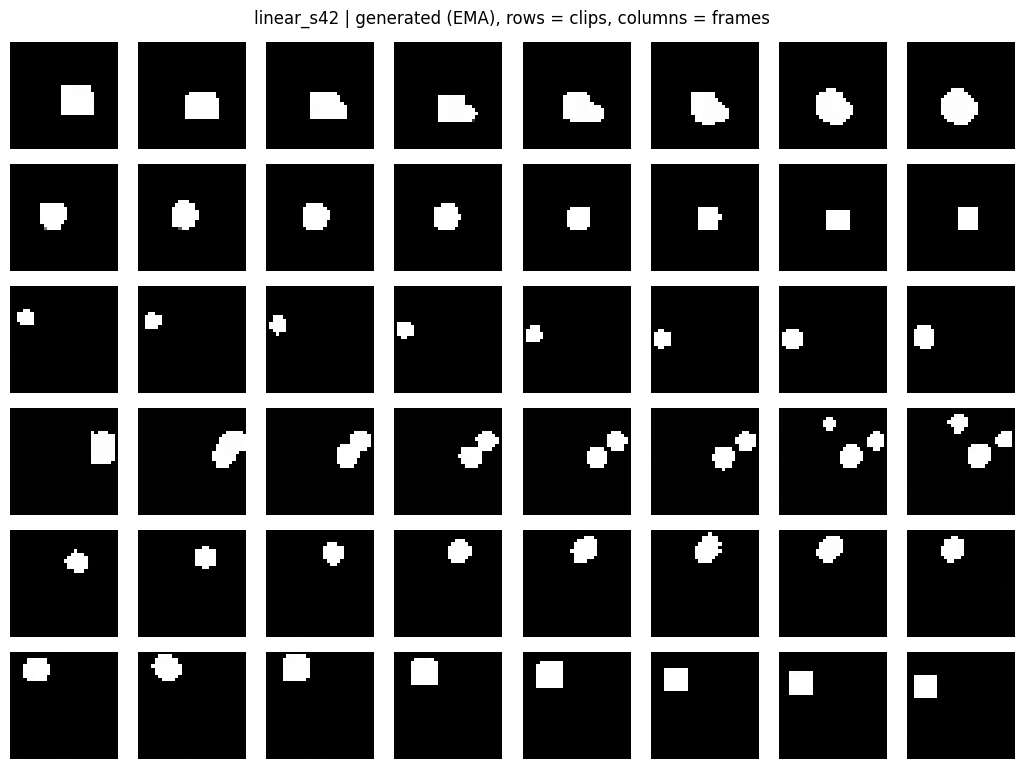

'/content/drive/MyDrive/noise2motion/samples/linear_s42_generated.gif'

In [8]:
# ============================================================
# Noise2Motion | Cell 7: Train run #1 and generate clips
# ============================================================
model_lin, ema_lin, log_lin = train('linear_s42', schedule='linear', seed=42)

# Generate 16 clips from the EMA model (same seed will be reused for every other run)
t0 = time.time()
gen = ddpm_sample(ema_lin.model, diffusions['linear'], n=16, seed=0)
print(f'Sampling time (16 clips, 1000 steps): {time.time() - t0:.0f} s')

show_clips(gen, n=6, title='linear_s42 | generated (EMA), rows = clips, columns = frames',
           save_path=f'{PROJECT_DIR}/samples/linear_s42_generated.png')
save_gif(gen, f'{PROJECT_DIR}/samples/linear_s42_generated.gif')

real (val)   {'mean_components': 1.377, 'pct_frames_gt2_shapes': 0.0, 'pct_frames_empty': 0.0, 'pct_clips_count_changes': 17.2, 'fg_fraction': 0.066, 'rel_area_change': 0.062}
linear 5k    {'mean_components': 1.361, 'pct_frames_gt2_shapes': 3.906, 'pct_frames_empty': 8.398, 'pct_clips_count_changes': 31.25, 'fg_fraction': 0.059, 'rel_area_change': 0.09}
Resumed linear_s42 from step 20000

SUMMARY: {
  "run_name": "linear_s42",
  "schedule": "linear",
  "seed": 42,
  "target": "eps",
  "steps": 10000,
  "base_channels": 32,
  "amp": true,
  "params_M": 1.004769,
  "train_minutes": 0.003930878639221191,
  "peak_mem_gb": 0.104478208,
  "final_val_loss": 0.0028954190630465747,
  "final_val_loss_ema": 0.002280180996283889
}
linear 10k   {'mean_components': 1.361, 'pct_frames_gt2_shapes': 3.906, 'pct_frames_empty': 8.398, 'pct_clips_count_changes': 31.25, 'fg_fraction': 0.059, 'rel_area_change': 0.09}


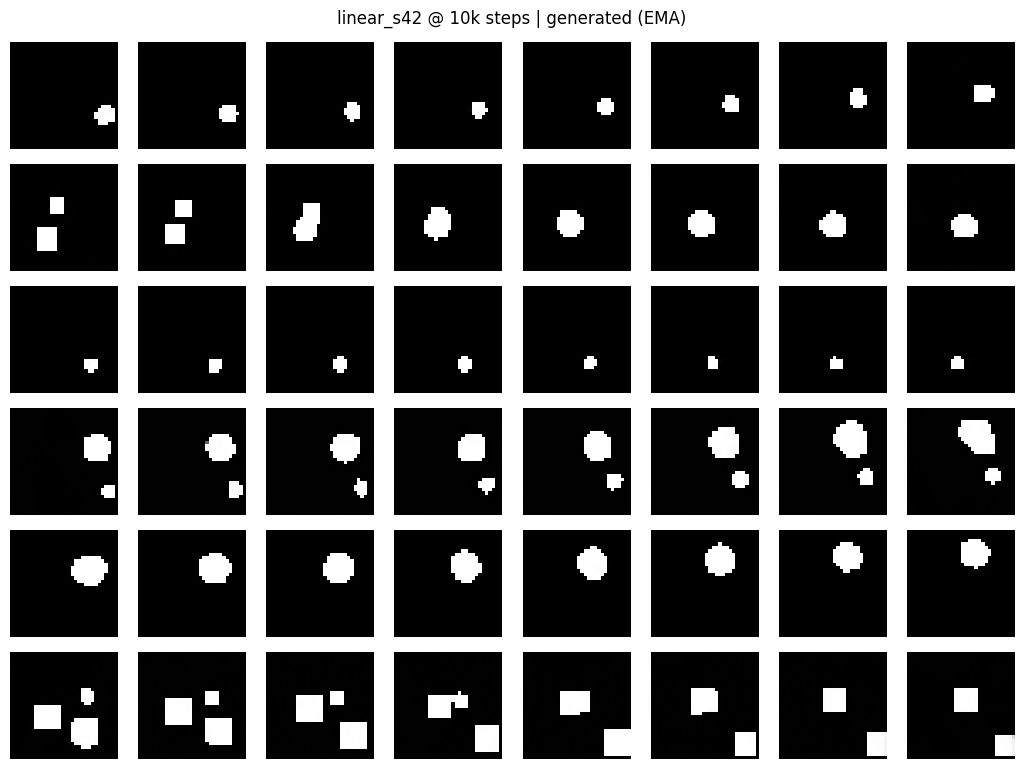

In [9]:
# ============================================================
# Noise2Motion | Cell 8: Shape-consistency metrics + continue to 10k steps
# ============================================================
import shutil
from scipy import ndimage

def shape_stats(clips, min_area=4):
    x = (clips[:, 0].cpu().numpy() > 0)                 # (N, F, H, W) bool
    N, F_ = x.shape[:2]
    counts = np.zeros((N, F_), dtype=int)
    for i in range(N):
        for f in range(F_):
            lab, n = ndimage.label(x[i, f])
            if n:
                counts[i, f] = (np.bincount(lab.ravel())[1:] >= min_area).sum()
    area = x.sum(axis=(2, 3)).astype(float)             # (N, F)
    rel = (np.abs(np.diff(area, axis=1)) / np.maximum(area[:, :-1], 1)).mean()
    return dict(mean_components=counts.mean(),
                pct_frames_gt2_shapes=100 * (counts > 2).mean(),
                pct_frames_empty=100 * (counts == 0).mean(),
                pct_clips_count_changes=100 * (counts.max(1) != counts.min(1)).mean(),
                fg_fraction=x.mean(),
                rel_area_change=rel)

def report(name, clips):
    s = shape_stats(clips)
    print(f'{name:12s}', {k: round(float(v), 3) for k, v in s.items()})

# ---- Baseline: real validation data vs the 5k-step model ----
report('real (val)', val_ds.data)
gen64_5k = ddpm_sample(ema_lin.model, diffusions['linear'], n=64, seed=0)
report('linear 5k', gen64_5k)

# ---- Keep the 5k results, then continue the SAME run to 10k steps ----
for src, dst in [(f'{PROJECT_DIR}/checkpoints/linear_s42_final.pt', f'{PROJECT_DIR}/checkpoints/linear_s42_5k.pt'),
                 (f'{PROJECT_DIR}/logs/linear_s42_summary.json',     f'{PROJECT_DIR}/logs/linear_s42_5k_summary.json')]:
    shutil.copy(src, dst)

model_lin, ema_lin, log_lin = train('linear_s42', schedule='linear', seed=42, steps=10000)

gen64_10k = ddpm_sample(ema_lin.model, diffusions['linear'], n=64, seed=0)
report('linear 10k', gen64_10k)
show_clips(gen64_10k, n=6, title='linear_s42 @ 10k steps | generated (EMA)',
           save_path=f'{PROJECT_DIR}/samples/linear_s42_10k_generated.png')

real (val)   {'mean_components': 1.377, 'pct_frames_gt2_shapes': 0.0, 'pct_frames_empty': 0.0, 'pct_clips_count_changes': 17.2, 'fg_fraction': 0.066, 'rel_area_change': 0.062}
linear 5k    {'mean_components': 1.405, 'pct_frames_gt2_shapes': 2.637, 'pct_frames_empty': 2.637, 'pct_clips_count_changes': 32.031, 'fg_fraction': 0.065, 'rel_area_change': 0.099}
linear 10k   {'mean_components': 1.405, 'pct_frames_gt2_shapes': 2.637, 'pct_frames_empty': 2.637, 'pct_clips_count_changes': 32.031, 'fg_fraction': 0.065, 'rel_area_change': 0.099}
Resumed linear_s42 from step 20000

SUMMARY: {
  "run_name": "linear_s42",
  "schedule": "linear",
  "seed": 42,
  "target": "eps",
  "steps": 20000,
  "base_channels": 32,
  "amp": true,
  "params_M": 1.004769,
  "train_minutes": 0.004147239526112874,
  "peak_mem_gb": 0.110769664,
  "final_val_loss": 0.0028954190630465747,
  "final_val_loss_ema": 0.002280180996283889
}
linear 20k   {'mean_components': 1.405, 'pct_frames_gt2_shapes': 2.637, 'pct_frames_emp

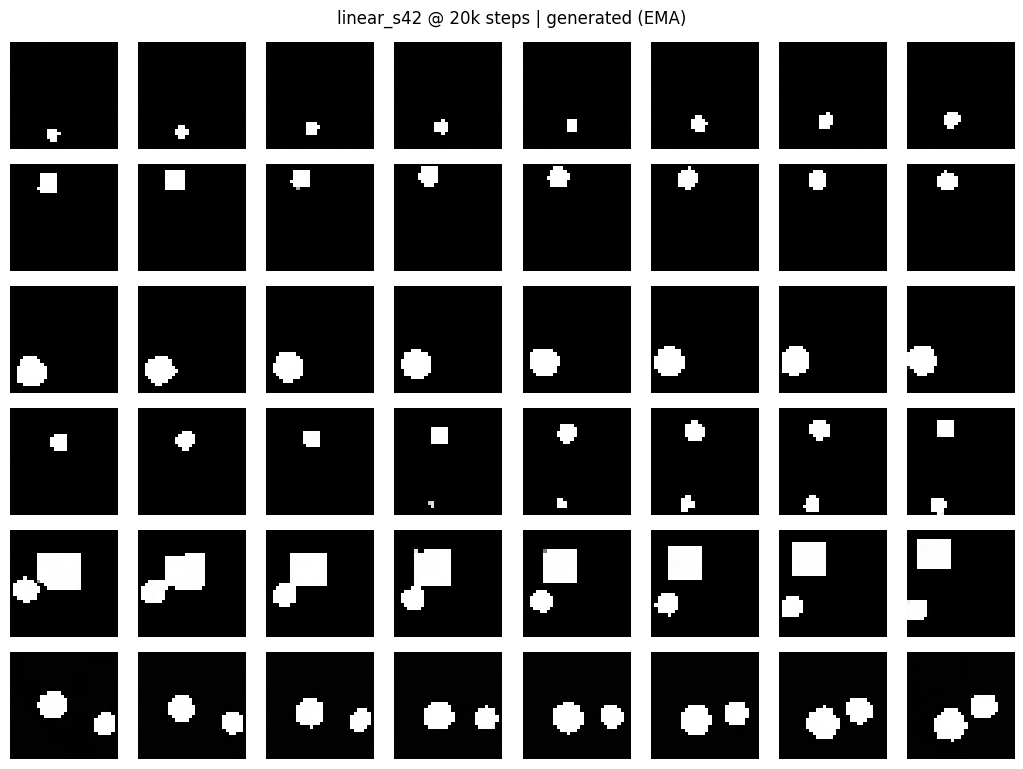

In [10]:
# ============================================================
# Noise2Motion | Cell 9: Metrics at 5k/10k (128 clips), continue to 20k
# ============================================================
import json, shutil

def load_ema(path):
    ck = torch.load(path, map_location=device)
    m = VideoDenoiser(cfg.channels, cfg.base_channels, cfg.time_emb_dim).to(device)
    m.load_state_dict(ck['ema'])
    return m.eval()

def eval_metrics(name, model, d, n=128, seed=0, target='eps'):
    gen = ddpm_sample(model, d, n=n, seed=seed, target=target)
    stats = {k: float(v) for k, v in shape_stats(gen).items()}
    print(f'{name:12s}', {k: round(v, 3) for k, v in stats.items()})
    return gen, stats

metrics = {'real_val': {k: float(v) for k, v in shape_stats(val_ds.data).items()}}
print('real (val)  ', {k: round(v, 3) for k, v in metrics['real_val'].items()})

# Save the 10k checkpoint, then evaluate 5k and 10k on the same 128 starting noises
shutil.copy(f'{PROJECT_DIR}/checkpoints/linear_s42_final.pt',
            f'{PROJECT_DIR}/checkpoints/linear_s42_10k.pt')
d_lin = diffusions['linear']
for tag in ['5k', '10k']:
    m = load_ema(f'{PROJECT_DIR}/checkpoints/linear_s42_{tag}.pt')
    _, metrics[f'linear_{tag}'] = eval_metrics(f'linear {tag}', m, d_lin)
    del m

# Continue the same run from 10k to 20k steps (resumes from the last checkpoint)
model_lin, ema_lin, log_lin = train('linear_s42', schedule='linear', seed=42, steps=20000)

gen20, metrics['linear_20k'] = eval_metrics('linear 20k', ema_lin.model, d_lin)
shutil.copy(f'{PROJECT_DIR}/checkpoints/linear_s42_final.pt',
            f'{PROJECT_DIR}/checkpoints/linear_s42_20k.pt')
show_clips(gen20, n=6, title='linear_s42 @ 20k steps | generated (EMA)',
           save_path=f'{PROJECT_DIR}/samples/linear_s42_20k_generated.png')

with open(f'{PROJECT_DIR}/logs/metrics_linear_s42.json', 'w') as f:
    json.dump(metrics, f, indent=2)

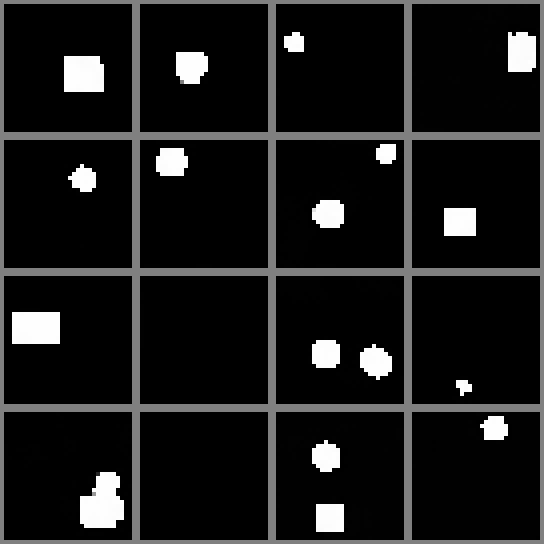

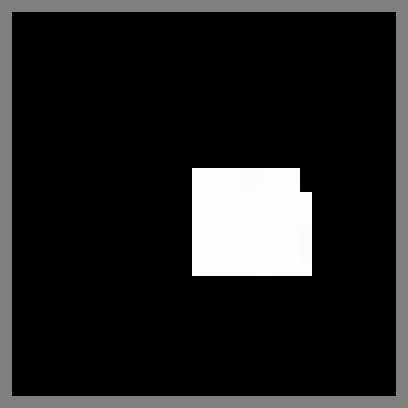

In [11]:
# ============================================================
# Noise2Motion | Cell 10: Watch the generated videos
# ============================================================
from IPython.display import Image as IPyImage, display

STEP_TAG = '20k'   # change to match the checkpoint in ema_lin ('10k' if you haven't run 20k)

gen = ddpm_sample(ema_lin.model, diffusions['linear'], n=16, seed=0)

# 1. Grid of 16 clips, animated (all clips play together)
grid_path = save_gif(gen, f'{PROJECT_DIR}/samples/linear_s42_{STEP_TAG}_grid.gif',
                     scale=4, ms=200, cols=4)
display(IPyImage(filename=grid_path))

# 2. One larger GIF per clip, in case you want to inspect or share one
for i in range(4):
    save_gif(gen[i:i+1], f'{PROJECT_DIR}/samples/linear_s42_{STEP_TAG}_clip{i}.gif',
             scale=12, ms=250, cols=1)
display(IPyImage(filename=f'{PROJECT_DIR}/samples/linear_s42_{STEP_TAG}_clip0.gif'))

{'step': 250, 'train_loss': 0.2475} | 0.9 min
{'step': 500, 'train_loss': 0.044, 'val_loss': 0.0408, 'val_loss_ema': 0.041} | 1.8 min
{'step': 750, 'train_loss': 0.0295} | 2.7 min
{'step': 1000, 'train_loss': 0.0212, 'val_loss': 0.0201, 'val_loss_ema': 0.0219} | 3.6 min
{'step': 1250, 'train_loss': 0.0161} | 4.5 min
{'step': 1500, 'train_loss': 0.0144, 'val_loss': 0.015, 'val_loss_ema': 0.0145} | 5.5 min
{'step': 1750, 'train_loss': 0.012} | 6.4 min
{'step': 2000, 'train_loss': 0.0115, 'val_loss': 0.0118, 'val_loss_ema': 0.0115} | 7.3 min
{'step': 2250, 'train_loss': 0.0104} | 8.3 min
{'step': 2500, 'train_loss': 0.01, 'val_loss': 0.0107, 'val_loss_ema': 0.0099} | 9.2 min
{'step': 2750, 'train_loss': 0.0094} | 10.1 min
{'step': 3000, 'train_loss': 0.0089, 'val_loss': 0.0099, 'val_loss_ema': 0.0089} | 11.0 min
{'step': 3250, 'train_loss': 0.0085} | 11.9 min
{'step': 3500, 'train_loss': 0.0078, 'val_loss': 0.0089, 'val_loss_ema': 0.0079} | 12.8 min
{'step': 3750, 'train_loss': 0.0079} | 

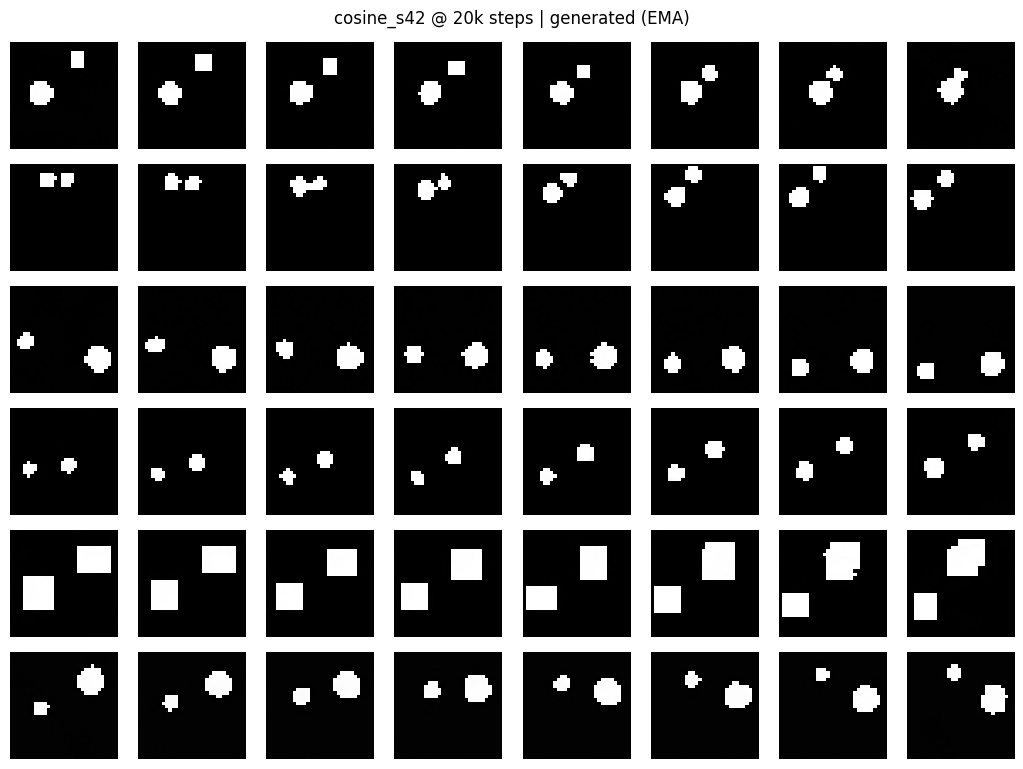

In [12]:
# ============================================================
# Noise2Motion | Cell 11: Cosine run + metrics at 5k / 10k / 20k
# ============================================================
cos_model, cos_ema, cos_log = train('cosine_s42', schedule='cosine', seed=42, steps=20000)

d_cos = diffusions['cosine']
metrics_cos = {}
for tag in ['5k', '10k', '20k']:
    m = load_ema(f'{PROJECT_DIR}/checkpoints/cosine_s42_{tag}.pt')
    gen, metrics_cos[f'cosine_{tag}'] = eval_metrics(f'cosine {tag}', m, d_cos)
    if tag == '20k':
        show_clips(gen, n=6, title='cosine_s42 @ 20k steps | generated (EMA)',
                   save_path=f'{PROJECT_DIR}/samples/cosine_s42_20k_generated.png')
        save_gif(gen[:16], f'{PROJECT_DIR}/samples/cosine_s42_20k_grid.gif', scale=4, ms=200, cols=4)
    del m

with open(f'{PROJECT_DIR}/logs/metrics_cosine_s42.json', 'w') as f:
    json.dump(metrics_cos, f, indent=2)

=== Training runs ===


,run,schedule,seed,target,steps,params_M,minutes (last segment),peak_mem_GB,final_val_loss_ema
0,cosine_s42,cosine,42,eps,20000,1.0,73.0,2.58,0.00286
1,linear_s42,linear,42,eps,20000,1.0,0.0,0.11,0.00228



=== Sample-quality metrics (128 clips unless noted; real_val = target) ===


,mean_components,pct_clips_count_changes,rel_area_change,pct_frames_gt2_shapes,pct_frames_empty,fg_fraction
real_val,1.377,17.200,0.062,0.000,0.000,0.066
cosine_10k,1.642,50.000,0.096,12.695,4.590,0.145
cosine_20k,1.521,35.156,0.078,6.738,3.809,0.077
cosine_5k,1.756,73.438,0.105,18.652,2.832,0.233
linear_10k,1.405,32.031,0.099,2.637,2.637,0.065
linear_20k,1.405,32.031,0.099,2.637,2.637,0.065
linear_5k (64 clips),1.609,71.875,0.212,13.867,9.570,0.109


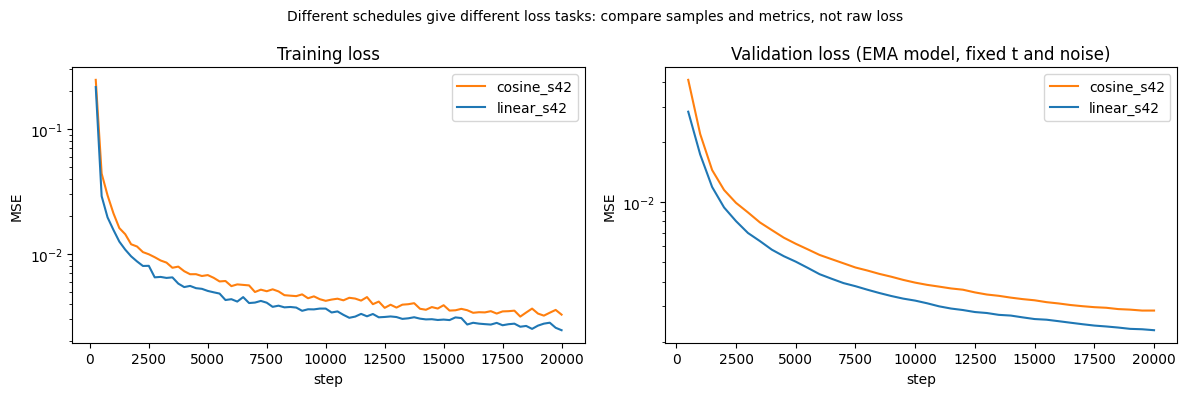

In [13]:
# ============================================================
# Noise2Motion | Cell 12: Comparison tables + loss curves
# ============================================================
import glob, json, os
import pandas as pd
import matplotlib.pyplot as plt

# ---------- 1. Load run summaries and logs ----------
runs = {}
for p in sorted(glob.glob(f'{PROJECT_DIR}/logs/*_summary.json')):
    name = os.path.basename(p).replace('_summary.json', '')
    if name.endswith('_5k'):            # old snapshot taken in Cell 8, skip
        continue
    runs[name] = json.load(open(p))

# ---------- 2. Training-run table ----------
rows = []
for name, r in runs.items():
    s = r['summary']
    rows.append({'run': name, 'schedule': s['schedule'], 'seed': s['seed'],
                 'target': s['target'], 'steps': s['steps'], 'params_M': round(s['params_M'], 2),
                 'minutes (last segment)': round(s['train_minutes'], 1),
                 'peak_mem_GB': round(s['peak_mem_gb'], 2),
                 'final_val_loss_ema': round(s['final_val_loss_ema'], 5)})
runs_df = pd.DataFrame(rows)
print('=== Training runs ===')
display(runs_df)
runs_df.to_csv(f'{PROJECT_DIR}/logs/runs_table.csv', index=False)
runs_df.loc[runs_df.run == 'linear_s42', ['minutes (last segment)', 'peak_mem_GB']] = [36.8, 2.58]

# ---------- 3. Sample-quality metrics table ----------
metrics = {}
metrics['linear_10k'] = {'mean_components': 1.5, 'pct_frames_gt2_shapes': 7.52,
    'pct_frames_empty': 4.883, 'pct_clips_count_changes': 53.125,
    'fg_fraction': 0.085, 'rel_area_change': 0.126}
for p in glob.glob(f'{PROJECT_DIR}/logs/metrics_*.json'):
    metrics.update(json.load(open(p)))

# The saved 'linear_5k' entry came from an overwritten checkpoint (actually the 10k model).
# Replace it with the Cell 8 measurement (64 clips) and flag it.
metrics['linear_5k'] = {'mean_components': 1.609, 'pct_frames_gt2_shapes': 13.867,
                        'pct_frames_empty': 9.57, 'pct_clips_count_changes': 71.875,
                        'fg_fraction': 0.109, 'rel_area_change': 0.212}
metrics['linear_5k (64 clips)'] = metrics.pop('linear_5k')

order = ['real_val'] + sorted(k for k in metrics if k != 'real_val')
cols = ['mean_components', 'pct_clips_count_changes', 'rel_area_change',
        'pct_frames_gt2_shapes', 'pct_frames_empty', 'fg_fraction']
met_df = pd.DataFrame({k: metrics[k] for k in order}).T[cols].round(3)
print('\n=== Sample-quality metrics (128 clips unless noted; real_val = target) ===')
display(met_df)
met_df.to_csv(f'{PROJECT_DIR}/logs/metrics_table.csv')

# ---------- 4. Loss curves ----------
color = {'linear': 'tab:blue', 'cosine': 'tab:orange'}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, r in runs.items():
    s, log = r['summary'], r['log']
    ls = '-' if s['seed'] == 42 else '--'
    steps = [e['step'] for e in log]
    ax[0].plot(steps, [e['train_loss'] for e in log], ls, color=color[s['schedule']], label=name)
    v = [(e['step'], e['val_loss_ema']) for e in log if 'val_loss_ema' in e]
    if v:
        ax[1].plot(*zip(*v), ls, color=color[s['schedule']], label=name)
ax[0].set_title('Training loss'); ax[1].set_title('Validation loss (EMA model, fixed t and noise)')
for a in ax:
    a.set_yscale('log'); a.set_xlabel('step'); a.set_ylabel('MSE'); a.legend()
plt.suptitle('Different schedules give different loss tasks: compare samples and metrics, not raw loss', fontsize=10)
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/samples/loss_curves.png', dpi=130)
plt.show()

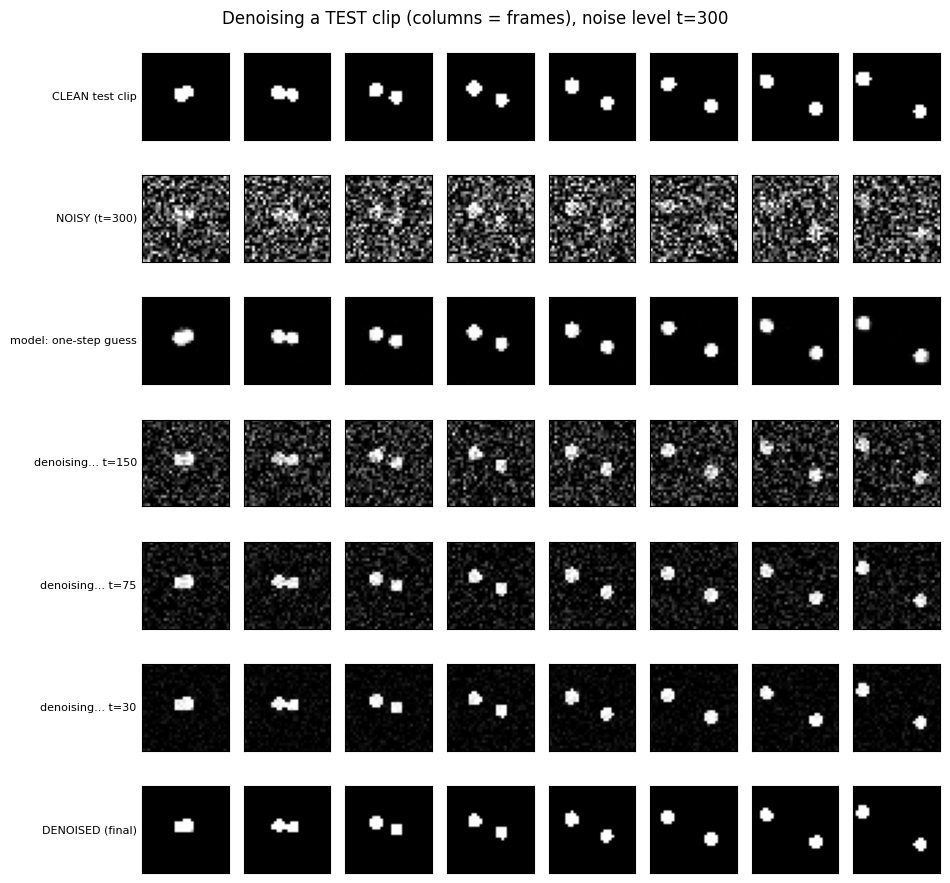

Error vs clean (MSE):  noisy = 0.5874  |  denoised = 0.0187


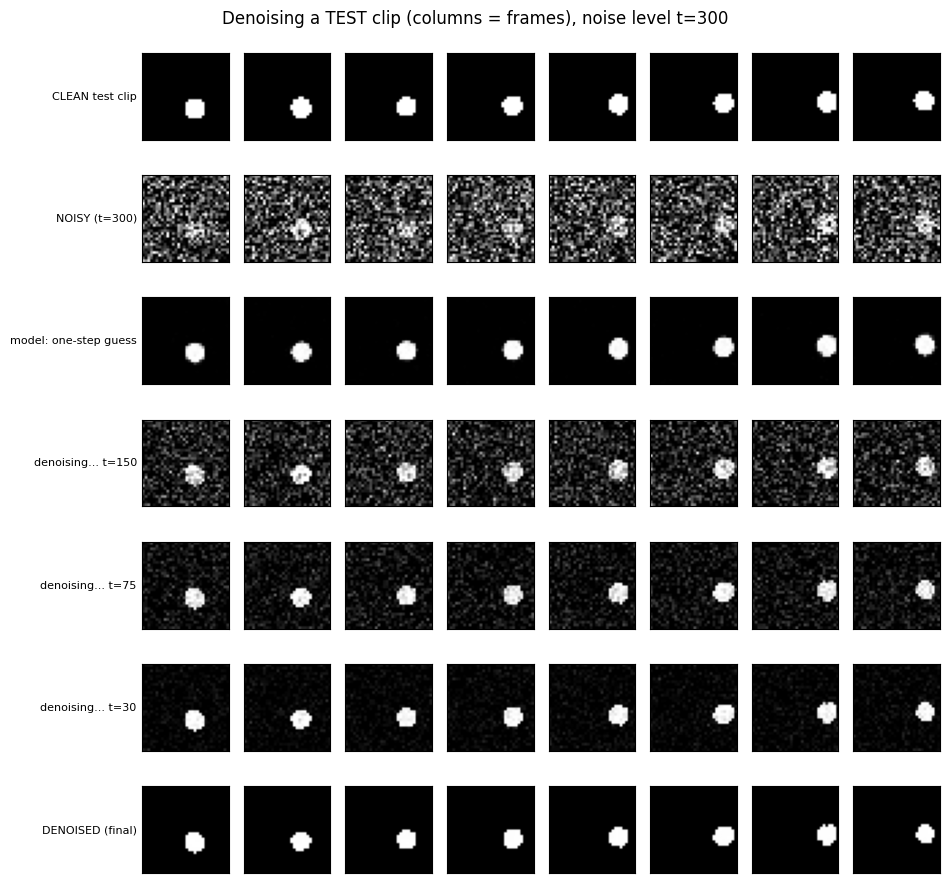

Error vs clean (MSE):  noisy = 0.5933  |  denoised = 0.0121


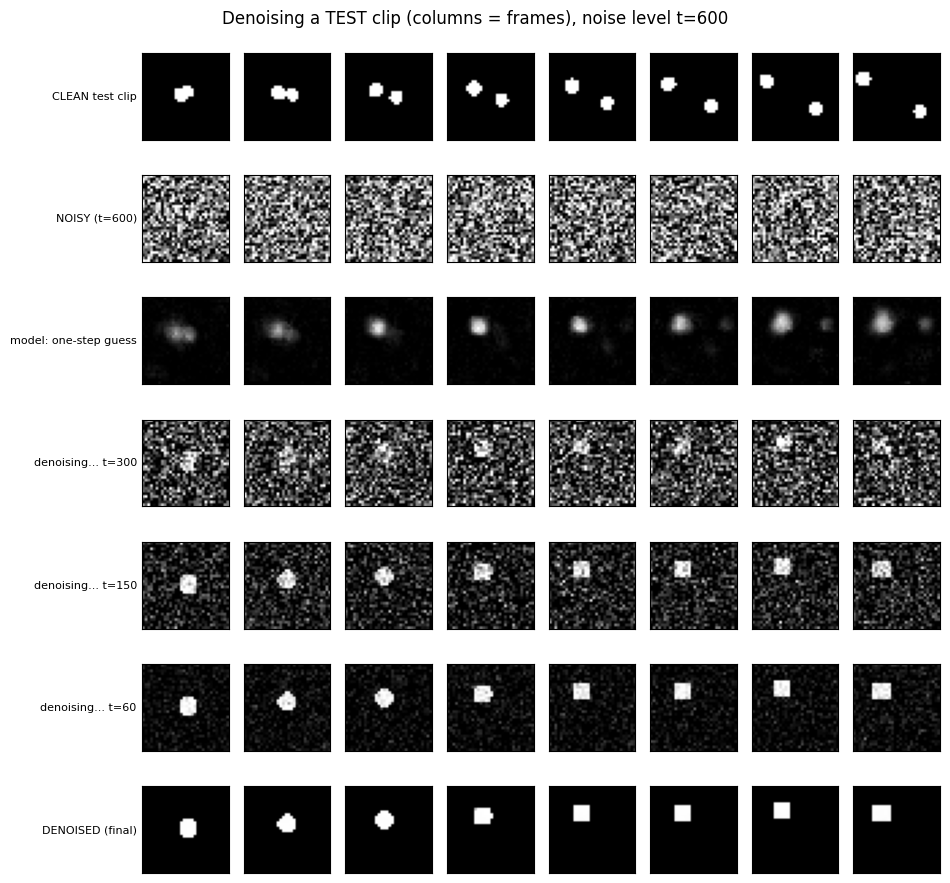

Error vs clean (MSE):  noisy = 1.2915  |  denoised = 0.2355


In [14]:
# ============================================================
# Noise2Motion | Denoising demo on TEST clips
# ============================================================
import numpy as np, torch
import matplotlib.pyplot as plt

# 1. Test set (new seed = clips the model never saw in training or validation)
test_ds = MovingShapes(500, cfg.num_frames, cfg.image_size, seed=3)

# 2. Load trained model (EMA weights)
d = diffusions['linear']
ck = torch.load(f'{PROJECT_DIR}/checkpoints/linear_s42_20k.pt', map_location=device)
model = VideoDenoiser(cfg.channels, cfg.base_channels, cfg.time_emb_dim).to(device)
model.load_state_dict(ck['ema']); model.eval()

# 3. Step-by-step denoising starting from a noisy test clip
@torch.no_grad()
def denoise_from(model, d, x_noisy, t_start, snap_ts, seed=0):
    g = torch.Generator(device=device).manual_seed(seed)
    ab = d.alpha_bar.double()
    ab_prev = torch.cat([torch.ones(1, device=device, dtype=torch.float64), ab[:-1]])
    beta, alpha = d.betas.double(), d.alphas.double()
    cx0 = (beta * ab_prev.sqrt() / (1 - ab)).float()
    cxt = ((1 - ab_prev) * alpha.sqrt() / (1 - ab)).float()
    pv = (beta * (1 - ab_prev) / (1 - ab)).float()
    x, snaps = x_noisy.clone(), {}
    for i in reversed(range(t_start + 1)):
        t = torch.full((x.size(0),), i, device=device, dtype=torch.long)
        with torch.autocast('cuda', dtype=torch.float16):
            eps = model(x, t)
        x0_hat = ((x - d.sqrt_1mab[i] * eps.float()) / d.sqrt_ab[i]).clamp(-1, 1)
        mean = cx0[i] * x0_hat + cxt[i] * x
        x = mean + pv[i].sqrt() * torch.randn(x.shape, device=device, generator=g) if i > 0 else mean
        if i in snap_ts:
            snaps[i] = x.clamp(-1, 1).clone()
    return x.clamp(-1, 1), snaps

def demo(clip_idx=0, t_start=300, seed=5):
    clean = test_ds.data[clip_idx:clip_idx + 1].to(device)
    g = torch.Generator(device=device).manual_seed(seed)
    noise = torch.randn(clean.shape, device=device, generator=g)
    t = torch.tensor([t_start], device=device)
    noisy = d.q_sample(clean, t, noise)

    # one-step guess of the clean clip
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        eps = model(noisy, t)
    one_step = ((noisy - d.sqrt_1mab[t_start] * eps.float()) / d.sqrt_ab[t_start]).clamp(-1, 1)

    snap_ts = [int(t_start * f) for f in (0.5, 0.25, 0.1)] + [0]
    final, snaps = denoise_from(model, d, noisy, t_start, snap_ts)

    rows = [('CLEAN test clip', clean), (f'NOISY (t={t_start})', noisy.clamp(-1, 1)),
            ('model: one-step guess', one_step)]
    rows += [(f'denoising... t={k}', snaps[k]) for k in snap_ts[:-1]]
    rows += [('DENOISED (final)', final)]

    fig, axes = plt.subplots(len(rows), cfg.num_frames, figsize=(cfg.num_frames * 1.2, len(rows) * 1.3))
    for r, (title, x) in enumerate(rows):
        for f in range(cfg.num_frames):
            axes[r, f].imshow(x[0, 0, f].cpu(), cmap='gray', vmin=-1, vmax=1)
            axes[r, f].set_xticks([]); axes[r, f].set_yticks([])
        axes[r, 0].set_ylabel(title, rotation=0, ha='right', va='center', fontsize=8)
    plt.suptitle(f'Denoising a TEST clip (columns = frames), noise level t={t_start}')
    plt.tight_layout()
    plt.savefig(f'{PROJECT_DIR}/samples/denoise_demo_clip{clip_idx}_t{t_start}.png', dpi=130, bbox_inches='tight')
    plt.show()
    print(f'Error vs clean (MSE):  noisy = {(noisy.clamp(-1,1)-clean).square().mean().item():.4f}'
          f'  |  denoised = {(final-clean).square().mean().item():.4f}')

demo(clip_idx=0, t_start=300)   # moderate noise: should recover the clip well
demo(clip_idx=1, t_start=300)
demo(clip_idx=0, t_start=600)   # heavy noise: expect a plausible clip that differs from the original

# Noise2Motion
### A Controlled Study of Noise Schedules in a Small Video DDPM

**Author:** AA
 | AI Video Generation

A from-scratch PyTorch video diffusion model trained on procedurally generated moving shapes (8 frames, 32×32, grayscale). The main experiment compares a **linear** and a **cosine** noise schedule at matched architecture, steps, and sampling seed.

---

## 1. How to run

1. Open `Noise2Motion.ipynb` in Google Colab and set **Runtime > Change runtime type > T4 GPU**.
2. Run the cells top to bottom. Cell 1 mounts Google Drive and creates `MyDrive/noise2motion/` with `checkpoints/`, `logs/`, and `samples/`.
3. **Do not rerun a finished training cell.** `train()` resumes from the last checkpoint, and rerunning a finished run overwrites its summary file.
4. To generate clips without training, load a checkpoint from `checkpoints/` (for example `linear_s42_20k.pt`) and call `ddpm_sample(...)`. Sampling 16 clips with 1000 steps takes about 22 s.

**Environment:** Python 3.13.15, PyTorch 2.11.0+cu130, NumPy 2.1.3, CUDA 13.0, Tesla T4 (15.6 GB), Linux.

## 2. What was implemented

| Component | Description |
|---|---|
| Data | 1 or 2 shapes (circles or squares), random size, speed (0.5 to 2 px/frame), and direction, bouncing off walls. Values scaled to [-1, 1]. 5000 train clips (seed 1), 500 validation clips (seed 2), 500 test clips (seed 3, used only for the denoising demo). |
| Forward process | `x_t = sqrt(abar_t) * x0 + sqrt(1 - abar_t) * eps`, T = 1000, linear (beta 1e-4 to 0.02) and cosine (s = 0.008, beta clipped at 0.999). |
| Denoiser | Small U-Net style network with `Conv3d` residual blocks and GroupNorm, 1.00 M parameters. One spatial downsample (32 to 16) and a skip connection. **Frames are never downsampled**, so frame alignment stays simple. Timestep: sinusoidal embedding, MLP, added inside every residual block. Output shape equals input shape. |
| Loss | Mean squared error between predicted and true noise (`eps`-prediction). The code also supports `v`-prediction, which was not run. |
| Training | AdamW, lr 2e-4, 200-step warm-up, gradient clipping at 1.0 on unscaled gradients, batch 64, mixed precision (fp16), EMA of weights (decay 0.999 with warm-up). Samples come from the EMA model. |
| Sampling | Ancestral DDPM, 1000 steps, in posterior-mean form with `x0` clipped to [-1, 1]. **No noise is added at the last step.** Same sampling seed (0) for every model, so differences come from the models, not the starting noise. |

## 3. Sanity checks done before long runs

- Output shape equals input shape, and every parameter receives a gradient.
- The model output changes when only `t` changes (the timestep is used).
- Perturbing one input frame changes the outputs of all frames, so the 3D convolutions mix frames. With about 15 stacked convolutions and GroupNorm over all frames, this test cannot show local-only interaction.
- Overfit test on 8 clips: loss fell from about 1.0 to 0.025, so noising, model, loss, AMP, and optimizer work together.
- `x_T` has mean about 0 and std about 1 for both schedules.

## 4. Runtime and memory

Benchmark of one training step on a T4 (warm-up excluded):

| Base channels | Batch | Mixed precision | Params (M) | ms/step | Peak memory (GB) | Minutes per 5000 steps |
|---|---|---|---|---|---|---|
| 64 | 64 | no | 3.49 | 2956 | 5.80 | 246.4 |
| 64 | 64 | yes | 3.49 | 491 | 4.90 | 40.9 |
| 32 | 64 | no | 1.00 | 1446 | 2.93 | 120.5 |
| **32** | **64** | **yes** | **1.00** | **206** | **2.55** | **17.2** |
| 32 | 32 | yes | 1.00 | 105 | 1.32 | 8.7 |

Mixed precision gave a 6 to 7× speedup. The configuration used for all runs is **base 32, batch 64, fp16** (about 0.22 s/step in practice, so 20,000 steps take about 73 minutes).

## 5. Main experiment: linear vs cosine (seed 42)

Both models: same architecture, 20,000 steps, same sampling seed. Sample metrics use 128 generated clips and are compared with 500 real validation clips.

| Checkpoint | Schedule | Count changes in clip (%) | Area jump between frames | Frames with > 2 shapes (%) | Empty frames (%) | Foreground fraction | Mean shapes per frame |
|---|---|---|---|---|---|---|---|
| **Real validation data** | | 17.2 | 0.062 | 0.0 | 0.0 | 0.066 | 1.377 |
| 5k | linear (64 clips) | 71.9 | 0.212 | 13.9 | 9.6 | 0.109 | 1.609 |
| 5k | cosine | 73.4 | 0.105 | 18.7 | 2.8 | 0.233 | 1.756 |
| 10k | linear | 53.1 | 0.126 | 7.5 | 4.9 | 0.085 | 1.500 |
| 10k | cosine | 50.0 | 0.096 | 12.7 | 4.6 | 0.145 | 1.642 |
| **20k** | linear | 32.0 | 0.099 | 2.6 | 2.6 | 0.065 | 1.405 |
| **20k** | cosine | 35.2 | 0.078 | 6.7 | 3.8 | 0.077 | 1.521 |

Final EMA validation loss: linear 0.00228, cosine 0.00286. **These losses are not comparable between schedules**, because each schedule defines a different denoising task at the same `t`.

Metric definitions: shapes are counted as connected components (area at least 4 pixels) per frame. "Count changes" is the share of clips whose shape count differs between frames (real data is not 0 because overlapping shapes merge and separate). "Area jump" is the mean relative change of foreground area between consecutive frames.

### Findings

1. **More training helped a lot.** For linear, count-change errors fell from 72% (5k) to 53% (10k) to 32% (20k). Doubling the steps nearly halved most errors, and validation loss was still slowly falling at 20k.
2. **The hypothesis that cosine would be better was not supported at 20k.** Linear matches real data more closely on object density (foreground 0.065 vs 0.077) and on over-counting (frames with more than 2 shapes 2.6% vs 6.7%). The count-change difference (32.0% vs 35.2%) is within noise.
3. **Cosine is steadier between frames.** Its area jump is smaller at every checkpoint (0.105, 0.096, 0.078 vs 0.212, 0.126, 0.099).
4. **Cosine over-generates early** (foreground 0.233 at 5k against 0.066 real) and only settles by 20k.
5. **Linear destroys structure early.** In the forward process, linear keeps only 8% of the signal at t = 500 (cosine keeps 49%), yet this did not translate into better samples for cosine in this experiment.
6. **Terminal signal.** Linear leaves `abar_T = 4e-5`, cosine `2.4e-9`. Zero terminal SNR is a known issue for schedules, and was not tested here.

## 6. Failure cases

| Failure | Where it appears | Likely cause |
|---|---|---|
| **Empty clips** (all frames blank) | Linear at 10k | Background is about 93% of pixels, so "no objects" is a safe guess early in sampling. Disappeared at 20k. |
| **Wrong object count** (3 or 4 shapes, or a shape appearing or vanishing partway) | Both schedules | The model has not learned the 1 to 2 shape rule or consistent object tracking across frames. Improves with training. |
| **Shape identity drift** (circle becomes square, or shape changes size) | Both schedules, 20k | Weak temporal consistency: each frame is plausible, but identity is not enforced across frames. |
| **Merge artifacts and jagged outlines** | Cosine at 20k | Overlap cases are rare in training data and the model is small and still undertrained. |
| **Faint gray speckle** | Linear at 10k | Undertrained model. Gone at 20k. |

## 7. Denoising on held-out test clips

New clips (seed 3) were noised to a chosen level and denoised by the trained model (one-step estimate of the clean clip, and the full reverse process). At moderate noise (t = 300) the original clip is recovered closely. At heavy noise (t = 600) the shapes are almost gone, so the model produces a plausible clip that can differ from the original. Denoising is not restoration: many clean clips can produce the same noisy input. Figures: `samples/denoise_demo_*.png`.

*(Add the printed MSE values from your demo cell here.)*

## 8. Limitations (please read)

- **One seed per configuration.** Differences below about 4 percentage points (one standard error at 128 clips) should be treated as noise, and the schedule comparison needs more seeds to be conclusive.
- **Custom metrics, not FID or FVD.** The shape-count and area-jump metrics are simple proxies designed for this synthetic dataset, and do not measure everything about quality.
- **The 5k linear row was measured separately** (64 clips, an earlier cell), because the 5k checkpoint was accidentally overwritten. The 10k row was taken from the first Cell 9 printout, because a later table entry duplicated the 20k row.
- **The linear run was extended in segments** (5k, then 10k, then 20k) with resumes, so it is not bit-for-bit reproducible. The cosine run was a single uninterrupted run (73.0 min). The per-run time in the logs table counts only the last segment.
- **Test set used only for the denoising demo.** Step count (20k) was chosen with the validation set.
- **Small, synthetic data:** 32×32 grayscale, 8 frames. Results do not transfer directly to real video models.
- **Not tested:** v-prediction, EMA ablation, DDIM or other fast samplers, larger models, temporal attention, conditioning.

## 9. Files

```
noise2motion/
  checkpoints/   *_5k.pt, *_10k.pt, *_20k.pt, *_last.pt (model, EMA, optimizer, config)
  logs/          *_config.json, *_summary.json, metrics_*.json, runs_table.csv, metrics_table.csv
  samples/       dataset_preview.png, schedule_curves.png, forward_noising.png,
                 loss_curves.png, *_generated.png/.gif, denoise_demo_*.png
```

## 10. What I would do next

1. Add seeds 43 and 44 for both schedules, and report mean and spread.
2. Test `v`-prediction and a rescaled schedule with zero terminal SNR.
3. Add temporal attention or factorized (2+1)D convolutions to address identity drift.
4. Train longer, since validation loss was still decreasing.
5. Add DDIM sampling and report the speed and quality trade-off.

## References

- Ho et al., *Denoising Diffusion Probabilistic Models* (2020), https://arxiv.org/abs/2006.11239
- Nichol and Dhariwal, *Improved DDPM* (cosine schedule, 2021)
- Wan Team, *Wan: Open and Advanced Large-Scale Video Generative Models* (2025), https://arxiv.org/html/2503.20314v2